# GPU-accelerated conformer workflows with nvMolKit

**Note:** This is a guest post from Kevin Boyd at NVIDIA.

[nvMolKit](https://github.com/NVIDIA-BioNeMo/nvMolKit) is an open-source library
with GPU-accelerated implementations of common RDKit cheminformatics operations.
It provides RDKit-compatible Python APIs for running batched molecular operations
on NVIDIA GPUs. Installation and API details are in the
[nvMolKit documentation](https://nvidia-bionemo.github.io/nvMolKit/).

We previously demonstrated nvMolKit's fingerprinting, similarity, and clustering
functionality [here](https://greglandrum.github.io/rdkit-blog/posts/2026-02-28-nvmolkit-clustering.html).

Here, RDKit and nvMolKit run the same three-stage 3D workflow:

1. generate 50 conformers per molecule with ETKDGv3;
2. minimize every conformer with MMFF94;
3. calculate all-pairs torsion fingerprint deviation (TFD) matrices.

nvMolKit 0.6 adds the FIRE minimizer as an alternative to BFGS, so we'll include
both GPU minimizers and compare their results with RDKit.

## Installation

nvMolKit is available on conda-forge alongside RDKit and requires an NVIDIA GPU
with compute capability 7.0 or later. Both packages can be installed into the
same environment:

```bash
conda install -c conda-forge rdkit nvmolkit
```

The next cell imports the packages, confirms that CUDA is available, and records
the software versions and GPU used for the benchmark.

In [1]:
from pathlib import Path
from time import perf_counter
import gzip
import importlib.metadata
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from rdkit import Chem, rdBase
from rdkit.Chem import AllChem, rdDistGeom, TorsionFingerprints

from nvmolkit.embedMolecules import EmbedMolecules
from nvmolkit.mmffOptimization import MMFFOptimizeMoleculesConfs
from nvmolkit.tfd import GetTFDMatrices
from nvmolkit.types import FireOptions, HardwareOptions

print("Python:", platform.python_version())
print("RDKit:", rdBase.rdkitVersion)
print("nvMolKit:", importlib.metadata.version("nvmolkit"))
print("PyTorch:", torch.__version__)
assert torch.cuda.is_available(), "CUDA is required for nvMolKit"
print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.2
RDKit: 2025.09.6
nvMolKit: 0.6.0
PyTorch: 2.8.0+cu128
GPU: NVIDIA RTX 1000 Ada Generation Laptop GPU


## Configuration

The timing results were collected on an NVIDIA GeForce RTX 5080 with an AMD
Ryzen 9 9950X. A random 1,000-molecule Enamine REAL sample is included with
this post. Additional molecules are available from the
[Enamine REAL 10.4M sample](https://enamine.net/compound-collections/real-compounds/real-database-subsets).

In [6]:
# Number of molecules to process
n_mols = 20

# Conformers to generate per molecule
n_confs = 50

# CPU threads for multithreaded RDKit operations and nvMolKit preprocessing
n_cpu_threads = 6

# Force-field iteration limits
max_mmff_iters = 200
fire_iters = 400

# ETKDG random seed
random_seed = 42

smi_file = Path("../data/enamine_real_1000.cxsmiles.gz")
assert smi_file.exists(), f"Enamine REAL file not found: {smi_file}"

hardware_options = HardwareOptions(preprocessingThreads=n_cpu_threads, gpuIds=[0])

## Loading molecules

The bundled sample contains 1,000 randomly selected molecules for which RDKit has
complete MMFF parameters. Parsing, hydrogen addition, MMFF coverage checks, and
molecule copies are not timed.

In [7]:
mols = []
with gzip.open(smi_file, "rt") as inf:
    next(inf)
    for line in inf:
        mol = Chem.MolFromSmiles(line.split("\t", 1)[0])
        if mol is None:
            continue
        mol = Chem.AddHs(mol)
        if not AllChem.MMFFHasAllMoleculeParams(mol):
            continue
        mols.append(mol)
        if len(mols) == n_mols:
            break

assert len(mols) == n_mols, f"Expected {n_mols:,} molecules, loaded {len(mols):,}"
print(f"Loaded {len(mols):,} molecules")
print(f"Median heavy atoms: {np.median([m.GetNumHeavyAtoms() for m in mols]):.0f}")

Loaded 20 molecules
Median heavy atoms: 26


## ETKDG conformer generation

Both paths generate 50 conformers per molecule with ETKDGv3,
random-coordinate initialization, and the same seed.
RDKit parallelizes the 50 conformers of each molecule over 16 CPU threads;
nvMolKit processes the complete molecule batch on the GPU and uses 16 CPU
preprocessing threads.

Small untimed calls initialize both backends before measurement.

In [8]:
rd_params = rdDistGeom.ETKDGv3()
rd_params.useRandomCoords = True
rd_params.randomSeed = random_seed
rd_params.numThreads = n_cpu_threads

nv_params = rdDistGeom.ETKDGv3()
nv_params.useRandomCoords = True
nv_params.randomSeed = random_seed

rd_warmup = Chem.Mol(mols[0])
rdDistGeom.EmbedMultipleConfs(rd_warmup, numConfs=2, params=rd_params)
nv_warmup = [Chem.Mol(m) for m in mols[:4]]
EmbedMolecules(nv_warmup, nv_params, confsPerMolecule=2, hardwareOptions=hardware_options)
torch.cuda.synchronize()

In [9]:
rdkit_embedded = [Chem.Mol(m) for m in mols]
t0 = perf_counter()
for mol in rdkit_embedded:
    rdDistGeom.EmbedMultipleConfs(mol, numConfs=n_confs, params=rd_params)
rdkit_embed_time = perf_counter() - t0

rdkit_n_confs = sum(m.GetNumConformers() for m in rdkit_embedded)
print(f"RDKit ETKDG: {rdkit_embed_time:.2f} s ({rdkit_n_confs:,} conformers)")

RDKit ETKDG: 6.08 s (1,000 conformers)


In [10]:
nvmolkit_embedded = [Chem.Mol(m) for m in mols]
t0 = perf_counter()
EmbedMolecules(
    nvmolkit_embedded,
    nv_params,
    confsPerMolecule=n_confs,
    hardwareOptions=hardware_options,
)
torch.cuda.synchronize()
nvmolkit_embed_time = perf_counter() - t0

nvmolkit_n_confs = sum(m.GetNumConformers() for m in nvmolkit_embedded)
print(f"nvMolKit ETKDG: {nvmolkit_embed_time:.2f} s ({nvmolkit_n_confs:,} conformers)")

nvMolKit ETKDG: 44.38 s (1,000 conformers)


### ETKDG ensemble comparison

ETKDG generates stochastic conformer ensembles, so conformer IDs from the two
implementations are not paired. Instead, we score every generated conformer
with RDKit MMFF94 and compare each molecule's median energy per atom. 

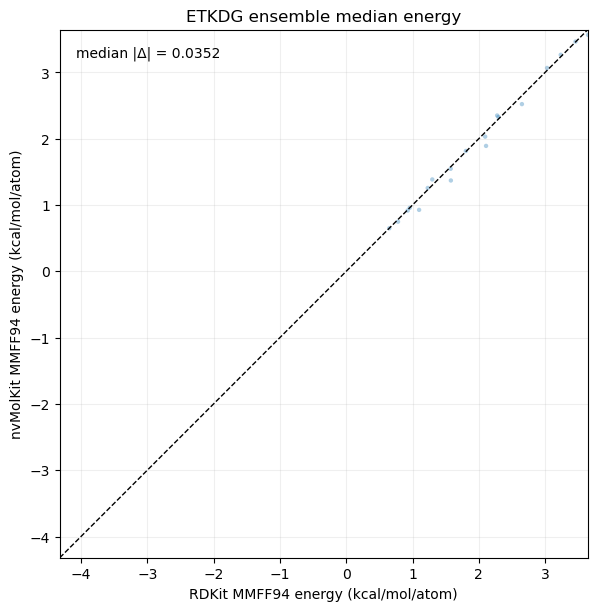

In [11]:
def mmff94_energies_per_atom(molecules):
    energy_groups = []
    for mol in molecules:
        props = AllChem.MMFFGetMoleculeProperties(mol, mmffVariant="MMFF94")
        energies = []
        for conf in mol.GetConformers():
            ff = AllChem.MMFFGetMoleculeForceField(
                mol,
                props,
                nonBondedThresh=100.0,
                confId=conf.GetId(),
                ignoreInterfragInteractions=True,
            )
            energies.append(ff.CalcEnergy() / mol.GetNumAtoms())
        energy_groups.append(np.asarray(energies))
    return energy_groups


def identity_panel(ax, x, y, title, annotation, *, full_range=False, scatter=False):
    finite = np.isfinite(x) & np.isfinite(y)
    x = np.asarray(x)[finite]
    y = np.asarray(y)[finite]
    if full_range:
        lower, upper = min(x.min(), y.min()), max(x.max(), y.max())
    else:
        lower = min(np.quantile(x, 0.001), np.quantile(y, 0.001))
        upper = max(np.quantile(x, 0.999), np.quantile(y, 0.999))
    if scatter:
        ax.scatter(x, y, s=10, alpha=0.35, edgecolors="none")
    else:
        ax.hexbin(x, y, gridsize=65, bins="log", mincnt=1, cmap="viridis")
    ax.plot([lower, upper], [lower, upper], color="black", linestyle="--", linewidth=1)
    ax.set(xlim=(lower, upper), ylim=(lower, upper), title=title)
    ax.set_aspect("equal", adjustable="box")
    ax.text(0.03, 0.97, annotation, transform=ax.transAxes, va="top")
    ax.grid(alpha=0.2)


rdkit_etkdg_energy_groups = mmff94_energies_per_atom(rdkit_embedded)
nvmolkit_etkdg_energy_groups = mmff94_energies_per_atom(nvmolkit_embedded)
rdkit_etkdg_medians = np.asarray([np.median(x) for x in rdkit_etkdg_energy_groups])
nvmolkit_etkdg_medians = np.asarray([np.median(x) for x in nvmolkit_etkdg_energy_groups])

fig, ax = plt.subplots(figsize=(6.5, 6), constrained_layout=True)
identity_panel(
    ax,
    rdkit_etkdg_medians,
    nvmolkit_etkdg_medians,
    "ETKDG ensemble median energy",
    f"median |Δ| = {np.median(np.abs(rdkit_etkdg_medians - nvmolkit_etkdg_medians)):.3g}",
    scatter=True,
)
ax.set_xlabel("RDKit MMFF94 energy (kcal/mol/atom)")
ax.set_ylabel("nvMolKit MMFF94 energy (kcal/mol/atom)")
plt.show()

## MMFF94 minimization: RDKit, nvMolKit BFGS, and nvMolKit FIRE

All three MMFF94 minimizations start from identical
coordinates: clones of the nvMolKit-generated conformers. Force-field
construction is included in each timing. RDKit and nvMolKit BFGS use 200
iterations. FIRE uses 400 iterations and a gradient tolerance of $10^{-4}$.

In [12]:
rdkit_ff_mols = [Chem.Mol(m) for m in nvmolkit_embedded]
nvmolkit_bfgs_mols = [Chem.Mol(m) for m in nvmolkit_embedded]
nvmolkit_fire_mols = [Chem.Mol(m) for m in nvmolkit_embedded]

t0 = perf_counter()
rdkit_ff_results = [
    AllChem.MMFFOptimizeMoleculeConfs(
        mol,
        numThreads=n_cpu_threads,
        maxIters=max_mmff_iters,
        nonBondedThresh=100.0,
        ignoreInterfragInteractions=True,
    )
    for mol in rdkit_ff_mols
]
rdkit_mmff_time = perf_counter() - t0
rdkit_status = np.array([status for result in rdkit_ff_results for status, _ in result])
print(f"RDKit MMFF: {rdkit_mmff_time:.2f} s; {(rdkit_status == 0).sum():,}/{len(rdkit_status):,} converged")

RDKit MMFF: 5.18 s; 85/1,000 converged


In [13]:
t0 = perf_counter()
nvmolkit_bfgs_results = MMFFOptimizeMoleculesConfs(
    nvmolkit_bfgs_mols,
    maxIters=max_mmff_iters,
    nonBondedThreshold=100.0,
    ignoreInterfragInteractions=True,
    hardwareOptions=hardware_options,
    minimizerKind="BFGS",
)
torch.cuda.synchronize()
nvmolkit_bfgs_time = perf_counter() - t0
print(f"nvMolKit BFGS ({max_mmff_iters} iterations): {nvmolkit_bfgs_time:.2f} s")

nvMolKit BFGS (200 iterations): 11.47 s


In [14]:
fire_options = FireOptions()
fire_options.gradTol = 1e-4

t0 = perf_counter()
nvmolkit_fire_results = MMFFOptimizeMoleculesConfs(
    nvmolkit_fire_mols,
    maxIters=fire_iters,
    nonBondedThreshold=100.0,
    ignoreInterfragInteractions=True,
    hardwareOptions=hardware_options,
    minimizerKind="FIRE",
    fireOptions=fire_options,
)
torch.cuda.synchronize()
nvmolkit_fire_time = perf_counter() - t0
print(f"nvMolKit FIRE ({fire_iters} iterations): {nvmolkit_fire_time:.2f} s")

nvMolKit FIRE (400 iterations): 6.39 s


### MMFF94 geometry comparison

The three minimizations started from identical coordinates. We independently
re-score every final geometry with RDKit MMFF94, then compare the RDKit result
with nvMolKit BFGS and FIRE. 

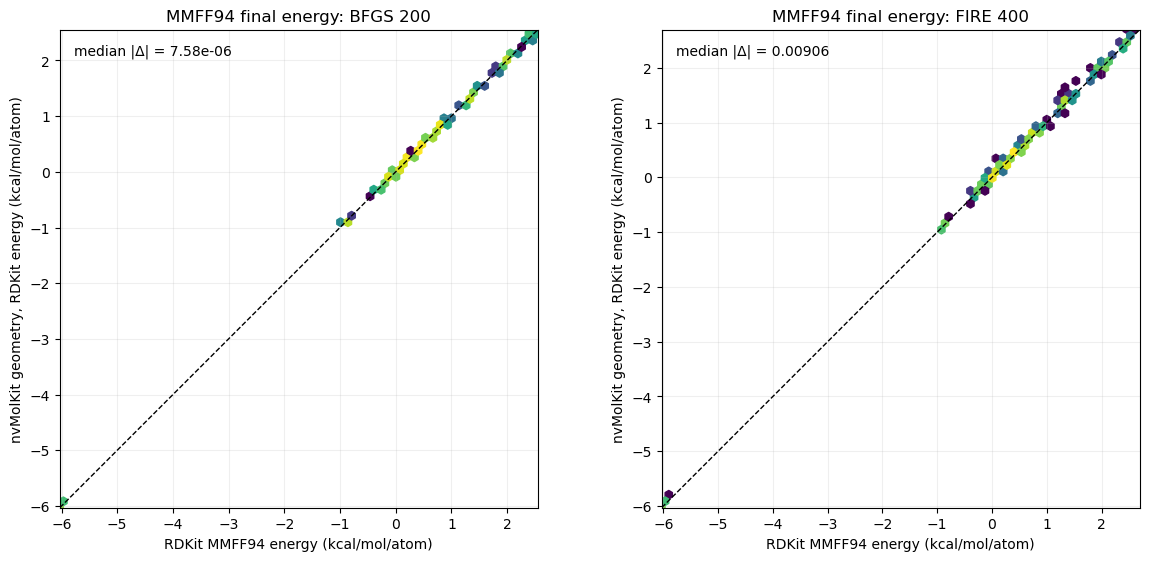

In [15]:
rdkit_final_energies = np.concatenate(mmff94_energies_per_atom(rdkit_ff_mols))
nvmolkit_bfgs_final_energies = np.concatenate(
    mmff94_energies_per_atom(nvmolkit_bfgs_mols)
)
nvmolkit_fire_final_energies = np.concatenate(
    mmff94_energies_per_atom(nvmolkit_fire_mols)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), constrained_layout=True)
identity_panel(
    axes[0],
    rdkit_final_energies,
    nvmolkit_bfgs_final_energies,
    f"MMFF94 final energy: BFGS {max_mmff_iters}",
    f"median |Δ| = {np.median(np.abs(rdkit_final_energies - nvmolkit_bfgs_final_energies)):.3g}",
)
identity_panel(
    axes[1],
    rdkit_final_energies,
    nvmolkit_fire_final_energies,
    f"MMFF94 final energy: FIRE {fire_iters}",
    f"median |Δ| = {np.median(np.abs(rdkit_final_energies - nvmolkit_fire_final_energies)):.3g}",
)
for ax in axes:
    ax.set_xlabel("RDKit MMFF94 energy (kcal/mol/atom)")
    ax.set_ylabel("nvMolKit geometry, RDKit energy (kcal/mol/atom)")
plt.show()

## Torsion fingerprint deviation matrices

The last stage calculates the complete torsion fingerprint deviation matrix for
each molecule. The same
BFGS-minimized coordinates are passed to both implementations after removing
explicit hydrogens. TFD is invariant to global molecular rotation and
translation and captures changes in the rotatable-bond torsions of the
conformer ensemble.

To test whether the small numerical differences affect a real downstream decision,
we independently cluster each implementation's TFD matrix with Butina at a 0.10
cutoff. The plot compares both the number of retained conformers and whether the
same conformer IDs are selected as cluster representatives.

RDKit TFD: 0.16 s
nvMolKit TFD: 0.010 s
TFD values within 0.01: 100.00%


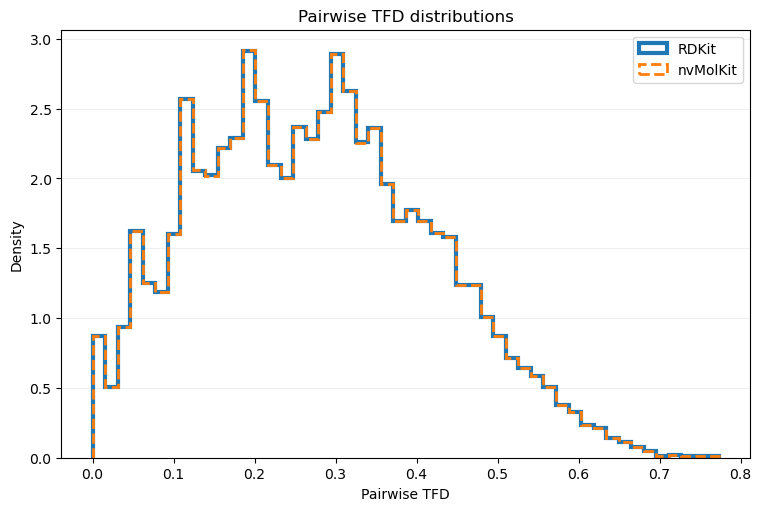

In [20]:
rdkit_tfd_mols = [Chem.RemoveHs(Chem.Mol(m)) for m in nvmolkit_bfgs_mols]
nvmolkit_tfd_mols = [Chem.Mol(m) for m in rdkit_tfd_mols]

t0 = perf_counter()
nvmolkit_tfd_results = GetTFDMatrices(nvmolkit_tfd_mols, return_type="numpy")
torch.cuda.synchronize()
nvmolkit_tfd_time = perf_counter() - t0

t0 = perf_counter()
rdkit_tfd_results = [
    TorsionFingerprints.GetTFDMatrix(mol, useWeights=True, maxDev="equal")
    for mol in rdkit_tfd_mols
]
rdkit_tfd_time = perf_counter() - t0

tfd_pairs = [
    (np.asarray(rd), np.asarray(nv))
    for rd, nv in zip(rdkit_tfd_results, nvmolkit_tfd_results)
    if len(rd)
]
rdkit_tfd_values = np.concatenate([rd for rd, _ in tfd_pairs])
nvmolkit_tfd_values = np.concatenate([nv for _, nv in tfd_pairs])
tfd_abs_differences = np.abs(rdkit_tfd_values - nvmolkit_tfd_values)
print(f"RDKit TFD: {rdkit_tfd_time:.2f} s")
print(f"nvMolKit TFD: {nvmolkit_tfd_time:.3f} s")
print(f"TFD values within 0.01: {np.mean(tfd_abs_differences <= 0.01):.2%}")

tfd_histogram_bins = np.linspace(
    min(rdkit_tfd_values.min(), nvmolkit_tfd_values.min()),
    max(rdkit_tfd_values.max(), nvmolkit_tfd_values.max()),
    51,
)
fig, ax = plt.subplots(figsize=(7.5, 5), constrained_layout=True)
ax.hist(
    rdkit_tfd_values,
    bins=tfd_histogram_bins,
    density=True,
    histtype="step",
    linewidth=3,
    label="RDKit",
)
ax.hist(
    nvmolkit_tfd_values,
    bins=tfd_histogram_bins,
    density=True,
    histtype="step",
    linewidth=2,
    linestyle="--",
    label="nvMolKit",
)
ax.set(
    xlabel="Pairwise TFD",
    ylabel="Density",
    title="Pairwise TFD distributions",
)
ax.grid(axis="y", alpha=0.2)
ax.legend()
plt.show()

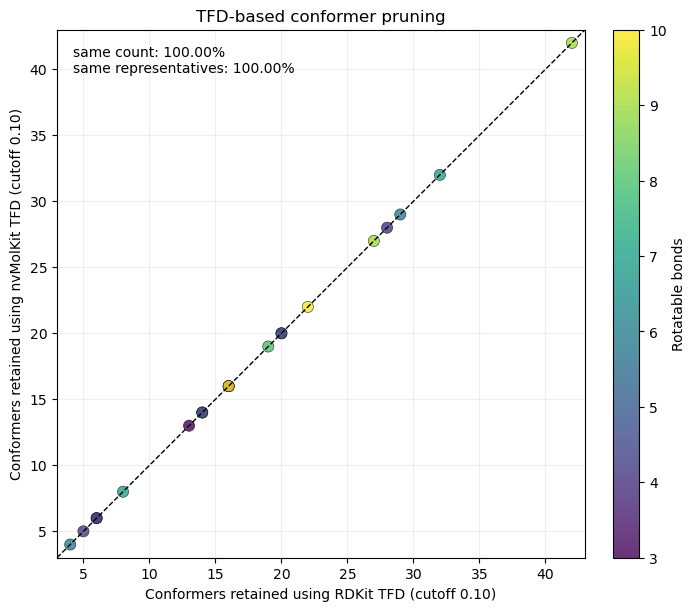

RDKit and nvMolKit TFD within 0.01: 100.00%


In [21]:
from rdkit.Chem import rdMolDescriptors
from rdkit.ML.Cluster import Butina


# Apply the same practical conformer-pruning decision to each TFD implementation.
tfd_pruning_cutoff = 0.10
tfd_pruning_data = []
for mol, rdkit_distances, nvmolkit_distances in zip(
    rdkit_tfd_mols, rdkit_tfd_results, nvmolkit_tfd_results
):
    rdkit_distances = np.asarray(rdkit_distances)
    nvmolkit_distances = np.asarray(nvmolkit_distances)
    if not len(rdkit_distances):
        continue

    n = mol.GetNumConformers()
    rdkit_clusters = Butina.ClusterData(
        rdkit_distances, n, tfd_pruning_cutoff, isDistData=True
    )
    nvmolkit_clusters = Butina.ClusterData(
        nvmolkit_distances, n, tfd_pruning_cutoff, isDistData=True
    )
    tfd_pruning_data.append(
        {
            "rdkit_count": len(rdkit_clusters),
            "nvmolkit_count": len(nvmolkit_clusters),
            "same_representatives": {
                cluster[0] for cluster in rdkit_clusters
            }
            == {cluster[0] for cluster in nvmolkit_clusters},
            "n_rotors": rdMolDescriptors.CalcNumRotatableBonds(mol),
        }
    )

rdkit_retained = np.asarray([item["rdkit_count"] for item in tfd_pruning_data])
nvmolkit_retained = np.asarray([item["nvmolkit_count"] for item in tfd_pruning_data])
rotor_counts = np.asarray([item["n_rotors"] for item in tfd_pruning_data])
same_count = rdkit_retained == nvmolkit_retained
same_representatives = np.asarray(
    [item["same_representatives"] for item in tfd_pruning_data]
)

lower = min(rdkit_retained.min(), nvmolkit_retained.min()) - 1
upper = max(rdkit_retained.max(), nvmolkit_retained.max()) + 1
fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)
points = ax.scatter(
    rdkit_retained,
    nvmolkit_retained,
    c=rotor_counts,
    cmap="viridis",
    s=65,
    alpha=0.8,
    edgecolors="black",
    linewidths=0.4,
)
ax.plot([lower, upper], [lower, upper], color="black", linestyle="--", linewidth=1)
ax.set(
    xlim=(lower, upper),
    ylim=(lower, upper),
    xlabel=f"Conformers retained using RDKit TFD (cutoff {tfd_pruning_cutoff:.2f})",
    ylabel=f"Conformers retained using nvMolKit TFD (cutoff {tfd_pruning_cutoff:.2f})",
    title="TFD-based conformer pruning",
)
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
ax.text(
    0.03,
    0.97,
    f"same count: {same_count.mean():.2%}\n"
    f"same representatives: {same_representatives.mean():.2%}",
    transform=ax.transAxes,
    va="top",
)
fig.colorbar(points, ax=ax, label="Rotatable bonds")
plt.show()

print(f"RDKit and nvMolKit TFD within 0.01: {np.mean(tfd_abs_differences <= 0.01):.2%}")


## Performance comparison

The workflow total is the sum of the three measured operations. Preparation, molecule
copying, warmup, validation re-scoring, and plotting are excluded.

In [22]:
timings = pd.DataFrame(
    {
        "RDKit": [
            rdkit_embed_time,
            rdkit_mmff_time,
            rdkit_tfd_time,
        ],
        f"nvMolKit BFGS {max_mmff_iters}": [
            nvmolkit_embed_time,
            nvmolkit_bfgs_time,
            nvmolkit_tfd_time,
        ],
        f"nvMolKit FIRE {fire_iters}": [
            nvmolkit_embed_time,
            nvmolkit_fire_time,
            nvmolkit_tfd_time,
        ],
    },
    index=["ETKDG", "MMFF94", "TFD"],
)
timings.loc["Total"] = timings.sum()
timings.loc["Speedup vs RDKit"] = timings.loc["Total", "RDKit"] / timings.loc["Total"]
timings

,RDKit,nvMolKit BFGS 200,nvMolKit FIRE 400
ETKDG,6.084060,44.375678,44.375678
MMFF94,5.181972,11.473166,6.389419
TFD,0.156530,0.009853,0.009853
Total,11.422561,55.858697,50.774949
Speedup vs RDKit,1.000000,0.204490,0.224965


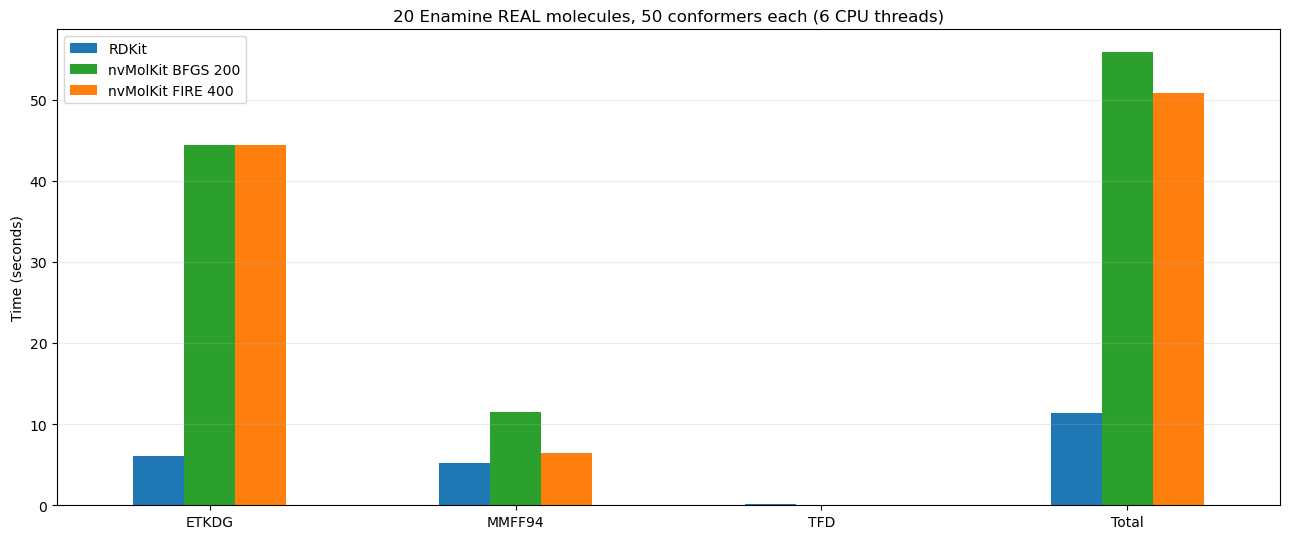

nvMolKit BFGS 200 workflow speedup: 0.20x
nvMolKit FIRE 400 workflow speedup: 0.22x


In [23]:
plot_timings = timings.loc[["ETKDG", "MMFF94", "TFD", "Total"]]
ax = plot_timings.plot.bar(
    figsize=(13, 5.5),
    color=["#1f77b4", "#2ca02c", "#ff7f0e"],
)
ax.set_ylabel("Time (seconds)")
ax.set_yscale("log")
ax.set_title(f"{n_mols:,} Enamine REAL molecules, {n_confs} conformers each ({n_cpu_threads} CPU threads)")
ax.set_xticklabels(plot_timings.index, rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

for label in timings.columns[1:]:
    print(f"{label} workflow speedup: {timings.loc['Speedup vs RDKit', label]:.2f}x")

## Appendix: choosing the FIRE iteration budget

nvMolKit ships FIRE as an alternative to BFGS; it provides a significant per-step performance increase. However, convergence on drug-like small molecules is typically slower than with BFGS, so users should measure desired versus achieved fidelity when choosing between BFGS and FIRE and determining the number of iterations.

For this notebook, we evaluated FIRE at 200, 400, and 600 iterations on a separate set of 500
Enamine REAL molecules with 50 conformers per molecule. Every optimizer starts
from the same nvMolKit ETKDG coordinates, and the final BFGS and FIRE geometries
are independently re-scored with RDKit MMFF94.

From these data, we chose 400 FIRE iterations as a reasonable approximation of BFGS accuracy; for users, the appropriate value will be application-specific.

| FIRE iterations | FIRE lower | median $\Delta E$/atom | median $|\Delta E|$/atom | within $10^{-4}$/atom | within $10^{-3}$/atom |
|---:|---:|---:|---:|---:|---:|
| 200 | 1.816% | 7.137e-3 | 7.610e-3 | 8.712% | 24.404% |
| 400 | 18.240% | 5.725e-5 | 8.972e-5 | 50.768% | 66.460% |
| 600 | 48.896% | 1.430e-8 | 9.749e-7 | 74.604% | 81.996% |

The signed difference is `(FIRE - BFGS) / atom`, so negative values favor FIRE.
At 600 iterations the
median signed difference is effectively zero and the median absolute difference
is below $10^{-6}$ kcal/mol/atom. FIRE finds a lower-energy well for roughly half
of the conformers.

![FIRE versus BFGS final energies](images/nvmolkit_fire_energy_vs_energy.png)


![FIRE minus BFGS energy distributions](images/nvmolkit_fire_energy_difference_histograms.png)

The histograms show the central 99% of each signed-difference distribution.
Outliers are omitted only from the displayed ranges. 